# B27 修改模型后，怎样判断改进是否可靠？

任务：比较线性模型与加入三次多项式的分类器，用训练子样本重复实验、配对误差和区间避免只展示最好一次。

先修：B10、B16；配对比较、重采样与统计口径。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 固定测试与比较问题
用已知非线性机制的双月牙数据。训练和测试一次划分后固定；比较路线预先指定，不看测试结果调多项式阶数。标签是教学生成，不是真实业务事实。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
X, y = make_moons(n_samples=1200, noise=0.25, random_state=27)
tr, te = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=27)
seeds = list(range(8))
base_errors = []
new_errors = []
timings = []

## 2. 同一训练子样本上的配对比较
每个种子抽取训练集的80%，两种模型共享该子样本和测试集。去掉多项式就是消融对照；不同种子的测试结果不是完全独立，因为共享测试样本。

In [3]:
for seed in seeds:
    rng = np.random.default_rng(seed)
    subset = rng.choice(tr, size=int(0.8 * len(tr)), replace=False)
    base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
    improved = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LogisticRegression(C=1, max_iter=500))
    t0 = time.perf_counter()
    base.fit(X[subset], y[subset])
    base_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    improved.fit(X[subset], y[subset])
    new_time = time.perf_counter() - t0
    base_errors.append((base.predict(X[te]) != y[te]).astype(float))
    new_errors.append((improved.predict(X[te]) != y[te]).astype(float))
    timings.append((base_time, new_time))
base_errors = np.array(base_errors)
new_errors = np.array(new_errors)
per_seed_gain = base_errors.mean(1) - new_errors.mean(1)

## 3. 对测试样本做配对 bootstrap
先固定已训练的模型，再对每个测试样本的平均误差差值重采样。区间描述这些固定模型在独立同分布测试样本上的不确定性，不是完整训练算法总体保证；时间序列需区块重采样。

In [4]:
per_case_gain = (base_errors - new_errors).mean(axis=0)

def paired_bootstrap(values, seed=27, repeats=1500):
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(repeats, len(values)), replace=True).mean(1)
    return (np.quantile(samples, [0.025, 0.975]), samples)
interval, bootstrap = paired_bootstrap(per_case_gain)
assert interval[0] <= interval[1]

## 4. 报告收益、变异与成本
正差值表示新方案少犯错；若区间跨0，需要承认证据不足。训练成本、测试集构成和每次结果同时交付，不只保留最佳种子。

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(seeds, per_seed_gain)
axes[0].axhline(0, color='black')
axes[0].set_title('各训练子样本的准确率提升')
axes[1].hist(bootstrap, bins=30)
axes[1].axvline(interval[0], color='red')
axes[1].axvline(interval[1], color='red')
axes[1].set_title('配对 bootstrap 均值分布')
fig.tight_layout()
fig.savefig(OUT_DIR / 'uncertainty.png')
plt.close(fig)
np.savez(OUT_DIR / 'paired_errors.npz', baseline=base_errors, improved=new_errors, test_indices=te)
finish({'baseline_accuracy': float(1 - base_errors.mean()), 'improved_accuracy': float(1 - new_errors.mean()), 'mean_accuracy_gain': float(per_case_gain.mean()), 'paired_95_percent_interval': interval.tolist(), 'per_seed_gain': per_seed_gain.tolist(), 'mean_training_seconds': np.mean(timings, axis=0).tolist(), 'interval_scope': 'fixed trained models; iid test examples; not full training uncertainty'})

{
  "baseline_accuracy": 0.8684027777777777,
  "improved_accuracy": 0.8909722222222223,
  "mean_accuracy_gain": 0.022569444444444444,
  "paired_95_percent_interval": [
    -0.0006944444444444445,
    0.04618055555555556
  ],
  "per_seed_gain": [
    0.030555555555555544,
    0.022222222222222227,
    0.02500000000000001,
    0.024999999999999994,
    0.016666666666666663,
    0.01944444444444446,
    0.02777777777777779,
    0.013888888888888881
  ],
  "mean_training_seconds": [
    0.0018814874929375947,
    0.0036005125075462274
  ],
  "interval_scope": "fixed trained models; iid test examples; not full training uncertainty",
  "elapsed_seconds": 1.283
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

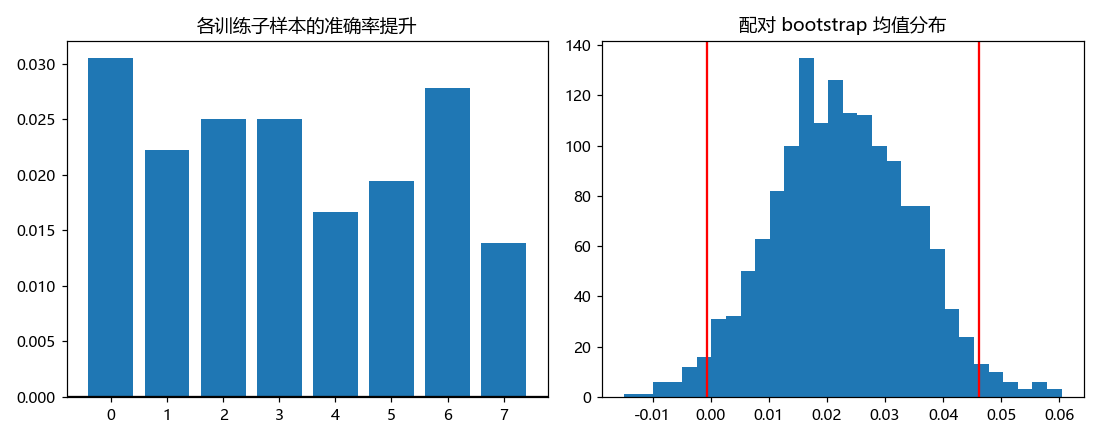

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
这里的区间条件于训练好的模型；不能把共享测试集的8个结果当8组独立测试数据。统计差异也不等于业务价值。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。